# 03 · Bayesian Networks with pgmpy

**Covers:** Lab Exercise 3 (spam network), Assignment 3 (Monty Hall, lung disease,
dice-and-coins game) and **d-separation**.

### Theory in one cell
- A Bayesian network is a **DAG** + one conditional probability table (CPD) per node.
- **Factorisation:** $P(X_1,\dots,X_n) = \prod_i P(X_i \mid \text{Parents}(X_i))$
- **Local Markov property:** every node is independent of its non-descendants given its parents.
- **d-separation:** X ⊥ Y | Z if **every** path between X and Y is blocked:

| Pattern | B not observed | B observed |
|---|---|---|
| Chain A → B → C | open | **blocked** |
| Fork A ← B → C | open | **blocked** |
| Collider A → B ← C | **blocked** | open (also if a *descendant* of B is observed) |

### pgmpy in 5 steps
1. `DiscreteBayesianNetwork([(parent, child), ...])`
2. `TabularCPD(...)` for every node, `model.add_cpds(...)`
3. `model.check_model()`
4. `VariableElimination(model).query(...)` / `.map_query(...)`
5. `model.is_dconnected(X, Y, observed=[...])`

In [1]:
# pgmpy is NOT pre-installed on Colab -> install it (locally it is already in the .venv)
%pip install -q pgmpy networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")                      # hide pgmpy deprecation warnings

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx                                  # to draw the graph
from itertools import product
from pathlib import Path
from scipy.stats import binom                          # binomial pmf for the coin game

from pgmpy.models import DiscreteBayesianNetwork       # (older pgmpy: BayesianNetwork)
from pgmpy.factors.discrete import TabularCPD          # conditional probability tables
from pgmpy.inference import VariableElimination        # exact inference

FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def draw_bn(model, pos, title, filename):
    """Draw a Bayesian network with networkx (works without graphviz) and save it."""
    plt.figure(figsize=(5, 3.8))
    nx.draw(nx.DiGraph(model.edges()), pos, with_labels=True, node_size=1500,
            node_color="#cfe2f3", arrowsize=20, font_weight="bold")
    plt.title(title)
    plt.savefig(FIG / filename, dpi=150, bbox_inches="tight")
    plt.show()

## How to read / write a `TabularCPD`  (the most common source of bugs!)

```
TabularCPD(variable, variable_card, values, evidence=[...], evidence_card=[...])
```
- **Rows** = states of the child variable.
- **Columns** = combinations of the parents. The **last** parent in `evidence` changes **fastest**
  (like counting in binary). With `evidence=["S", "L"]` the columns are
  (S=0,L=0), (S=0,L=1), (S=1,L=0), (S=1,L=1).
- Every **column** must sum to 1.
- Without `state_names` the states are 0, 1, …; with `state_names` you use the names in queries.

## Exercise 1 · E-mail spam network (Lab 3)

Structure: S → O, S → L, S → M, L → M (S = spam, O = word "offer", L = links, M = long).

| | value |
|---|---|
| P(S=1) | 0.4 |
| P(O=1 \| S=1), P(O=1 \| S=0) | 0.7, 0.1 |
| P(L=1 \| S=1), P(L=1 \| S=0) | 0.8, 0.3 |
| P(M=1 \| S, L) for (1,1),(1,0),(0,1),(0,0) | 0.9, 0.5, 0.6, 0.2 |

Model OK: True
+------+------+------+------+------+
| S    | S(0) | S(0) | S(1) | S(1) |
+------+------+------+------+------+
| L    | L(0) | L(1) | L(0) | L(1) |
+------+------+------+------+------+
| M(0) | 0.8  | 0.4  | 0.5  | 0.1  |
+------+------+------+------+------+
| M(1) | 0.2  | 0.6  | 0.5  | 0.9  |
+------+------+------+------+------+


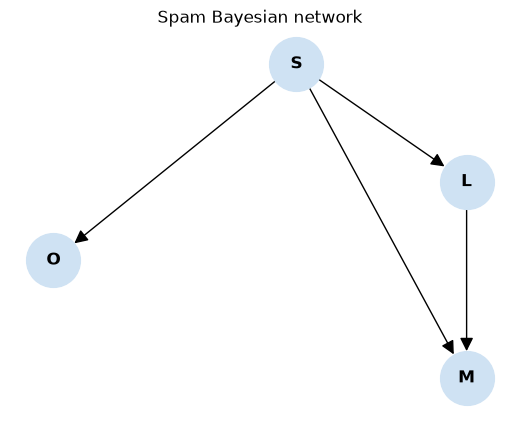

In [3]:
# 1) Structure: list of (parent, child) edges
spam_model = DiscreteBayesianNetwork([("S", "O"), ("S", "L"), ("S", "M"), ("L", "M")])

# 2) CPDs. Row 0 = P(var = 0 | ...), row 1 = P(var = 1 | ...)
cpd_s = TabularCPD("S", 2, [[0.6], [0.4]])                     # root node: one column
cpd_o = TabularCPD("O", 2, [[0.9, 0.3],                         # columns: S=0, S=1
                            [0.1, 0.7]], evidence=["S"], evidence_card=[2])
cpd_l = TabularCPD("L", 2, [[0.7, 0.2],
                            [0.3, 0.8]], evidence=["S"], evidence_card=[2])
#                            S=0,L=0  S=0,L=1  S=1,L=0  S=1,L=1   <- L changes fastest
cpd_m = TabularCPD("M", 2, [[0.8,     0.4,     0.5,     0.1],     # M = 0
                            [0.2,     0.6,     0.5,     0.9]],    # M = 1
                   evidence=["S", "L"], evidence_card=[2, 2])
spam_model.add_cpds(cpd_s, cpd_o, cpd_l, cpd_m)

# 3) Check that every CPD is consistent with the graph and every column sums to 1
print("Model OK:", spam_model.check_model())
print(cpd_m)
draw_bn(spam_model, {"S": (0, 1), "O": (-1, 0), "L": (0.7, 0.4), "M": (0.7, -0.6)},
        "Spam Bayesian network", "03_spam_network.png")

### a) Conditional independencies implied by the network
From the local Markov property (each node ⊥ non-descendants | parents):
- **O ⊥ L | S** and **O ⊥ M | S, L** → the word "offer" carries no extra information once we know whether it is spam.
- L and M are **not** independent given S (edge L → M).
- Without observing S, O and L are dependent (fork O ← S → L is open).

In [4]:
# pgmpy lists the local independencies for us
print(spam_model.local_independencies(["S", "O", "L", "M"]))

# is_dconnected(X, Y, observed) == True means "there is an active path" -> NOT independient
#Ponemos not (si no estan conectadas) son indepenedientes
print("O ⊥ L | S ?", not spam_model.is_dconnected("O", "L", observed=["S"]))
print("O ⊥ L     ?", not spam_model.is_dconnected("O", "L"))

(L ⟂ O | S)
(M ⟂ O | L, S)
(O ⟂ L, M | S)
O ⊥ L | S ? True
O ⊥ L     ? False


### b) Classification
For every combination of (O, L, M) compute $P(S=1\mid O,L,M)$ and say "spam" if it is > 0.5.
By the factorisation: $P(S\mid o,l,m) \propto P(S)\,P(o\mid S)\,P(l\mid S)\,P(m\mid S,l)$.

In [5]:
infer = VariableElimination(spam_model)

print(" O L M | P(spam|O,L,M) | class")
for o, l, m in product([0, 1], repeat=3):                 # all 8 possible e-mails
    posterior = infer.query(["S"], evidence={"O": o, "L": l, "M": m}, show_progress=False)
    p_spam = posterior.values[1]                           # values[1] = P(S = 1 | evidence)
    print(f" {o} {l} {m} |    {p_spam:.4f}     | {'SPAM' if p_spam > 0.5 else 'not spam'}")

 O L M | P(spam|O,L,M) | class
 0 0 0 |    0.0382     | not spam
 0 0 1 |    0.1370     | not spam
 0 1 0 |    0.1290     | not spam
 0 1 1 |    0.4706     | not spam
 1 0 0 |    0.4545     | not spam
 1 0 1 |    0.7692     | SPAM
 1 1 0 |    0.7568     | SPAM
 1 1 1 |    0.9492     | SPAM


## Exercise 2 · Monty Hall (Assignment 3, from the [pgmpy example](https://pgmpy.org/examples/Monty_Hall.html))

There are 3 doors, a car behind one. You pick a door, the host (who knows where the car
is) opens **another door with a goat**. Should you switch?

Network: `C` (contestant's choice) → `H` (host's door) ← `P` (prize door).
H is a **collider**: C and P are independent, but once H is observed they become
dependent – that is exactly why switching helps.

The host's CPD: if C ≠ P he must open the only remaining door (prob. 1); if C = P he opens
one of the two other doors with prob. 1/2 each; he never opens C or P.

In [6]:
monty = DiscreteBayesianNetwork([("C", "H"), ("P", "H")])
cpd_c = TabularCPD("C", 3, [[1/3], [1/3], [1/3]])            # contestant picks at random
cpd_p = TabularCPD("P", 3, [[1/3], [1/3], [1/3]])            # prize is anywhere
#  columns: (C=0,P=0) (C=0,P=1) (C=0,P=2) (C=1,P=0) ... (C=2,P=2)   <- P changes fastest
cpd_h = TabularCPD("H", 3,
                   [[0,   0,   0,   0,   0.5, 1,   0,   1,   0.5],   # host opens door 0
                    [0.5, 0,   1,   0,   0,   0,   1,   0,   0.5],   # host opens door 1
                    [0.5, 1,   0,   1,   0.5, 0,   0,   0,   0  ]],  # host opens door 2
                   evidence=["C", "P"], evidence_card=[3, 3])
monty.add_cpds(cpd_c, cpd_p, cpd_h)
print("Model OK:", monty.check_model())

# You chose door 0 and the host opened door 2: where is the prize?
print(VariableElimination(monty).query(["P"], evidence={"C": 0, "H": 2}, show_progress=False))
print("-> switching to door 1 wins with probability 2/3")

Model OK: True
+------+----------+
| P    |   phi(P) |
+======+==========+
| P(0) |   0.3333 |
+------+----------+
| P(1) |   0.6667 |
+------+----------+
| P(2) |   0.0000 |
+------+----------+
-> switching to door 1 wins with probability 2/3


## Exercise 3 · Lung disease (Assignment 3)

Network: B → T, B → X, B → D, T → D (B disease, T cough, X abnormal X-ray, D difficulty breathing).

**b) By hand:** X is not observed, so it is summed out and disappears:

$$P(B=1\mid T=1,D=1) = \frac{0.1\cdot0.8\cdot0.9}{0.1\cdot0.8\cdot0.9 + 0.9\cdot0.3\cdot0.5}
= \frac{0.072}{0.072+0.135}\approx 0.348$$

**c)** X depends only on B and B is observed ⇒ X ⊥ {T, D} | B, so
$P(X=1\mid B=0) = 0.1$ directly from the table.

Model OK: True


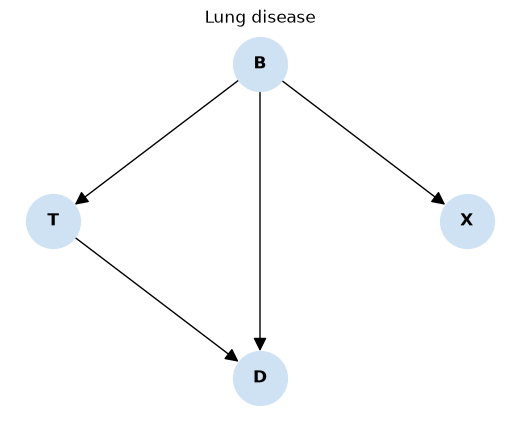

b) +------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+
   by hand: 0.3478
c) +------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+


In [7]:
lung = DiscreteBayesianNetwork([("B", "T"), ("B", "X"), ("B", "D"), ("T", "D")])
cpd_b = TabularCPD("B", 2, [[0.9], [0.1]])
cpd_t = TabularCPD("T", 2, [[0.7, 0.2], [0.3, 0.8]], evidence=["B"], evidence_card=[2])
cpd_x = TabularCPD("X", 2, [[0.9, 0.1], [0.1, 0.9]], evidence=["B"], evidence_card=[2])
#                            B=0,T=0  B=0,T=1  B=1,T=0  B=1,T=1
cpd_d = TabularCPD("D", 2, [[0.9,     0.5,     0.6,     0.1],
                            [0.1,     0.5,     0.4,     0.9]],
                   evidence=["B", "T"], evidence_card=[2, 2])
lung.add_cpds(cpd_b, cpd_t, cpd_x, cpd_d)
print("Model OK:", lung.check_model())
draw_bn(lung, {"B": (0, 1), "T": (-1, 0), "X": (1, 0), "D": (0, -1)}, "Lung disease", "03_lung.png")

infer = VariableElimination(lung)
print("b)", infer.query(["B"], evidence={"T": 1, "D": 1}, show_progress=False))
print("   by hand:", round(0.072 / (0.072 + 0.135), 4))
print("c)", infer.query(["X"], evidence={"B": 0}, show_progress=False))

## Exercise 4 · The dice-and-coins game (Assignment 3)

A fair coin decides who starts (J0 or J1). The starter rolls a die → n. The other player
tosses **his own** coin 2n times → m heads. The starter wins if n ≥ m.
J1's coin is biased: P(heads) = 4/7; J0's coin is fair.

Network: **S → M ← N** (S = starter, N = die, M = number of heads).
$M \mid S, N \sim \text{Binomial}(2N,\ p)$ with p = 4/7 if J0 started (J1 tosses) and p = 1/2 if J1 started.

In [8]:
# a) Simulation of 10,000 games
rng = np.random.default_rng(7)
coin = {0: 0.5, 1: 4 / 7}                 # P(heads) of the coin of player 0 and player 1
wins = np.zeros(2)
for _ in range(10_000):
    starter = rng.integers(2)             # 0 = J0, 1 = J1
    n = rng.integers(1, 7)                # the starter's die
    other = 1 - starter
    m = rng.binomial(2 * n, coin[other])  # the OTHER player tosses HIS coin 2n times
    winner = starter if n >= m else other
    wins[winner] += 1
print(f"a) P(J0 wins) ≈ {wins[0] / 1e4:.4f},  P(J1 wins) ≈ {wins[1] / 1e4:.4f}")

a) P(J0 wins) ≈ 0.4304,  P(J1 wins) ≈ 0.5696


In [9]:
# b) Bayesian network S -> M <- N
game = DiscreteBayesianNetwork([("S", "M"), ("N", "M")])
cpd_s = TabularCPD("S", 2, [[0.5], [0.5]], state_names={"S": ["J0", "J1"]})
cpd_n = TabularCPD("N", 6, [[1 / 6]] * 6, state_names={"N": [1, 2, 3, 4, 5, 6]})

# M can be 0..12. Build one column per (S, N) in the right order (N changes fastest).
columns = []
for s in (0, 1):                          # S = J0, then S = J1
    for n in range(1, 7):                 # N = 1..6
        p_heads = coin[1 - s]             # the other player's coin
        columns.append(binom.pmf(np.arange(13), 2 * n, p_heads))
cpd_m = TabularCPD("M", 13, np.array(columns).T,       # transpose: rows must be the states of M
                   evidence=["S", "N"], evidence_card=[2, 6],
                   state_names={"M": list(range(13)), "S": ["J0", "J1"], "N": [1, 2, 3, 4, 5, 6]})
game.add_cpds(cpd_s, cpd_n, cpd_m)
print("Model OK:", game.check_model())

# c) Who probably started, given that exactly one head was obtained?
print(VariableElimination(game).query(["S"], evidence={"M": 1}, show_progress=False))
print("-> J1 more likely started: one head is easier with J0's fair coin than with the 4/7 coin.")

Model OK: True
+-------+----------+
| S     |   phi(S) |
+=======+==========+
| S(J0) |   0.4529 |
+-------+----------+
| S(J1) |   0.5471 |
+-------+----------+
-> J1 more likely started: one head is easier with J0's fair coin than with the 4/7 coin.


### Key takeaways
- Comment the column order above every multi-parent CPD.
- `query` → posterior distribution; `map_query` → most probable joint assignment.
- `not model.is_dconnected(X, Y, observed=Z)` answers "X ⊥ Y | Z ?" — but also be ready to justify it path by path.